## Giai đoạn 1: Khám phá & Đánh giá Dữ liệu Ban đầu

In [ ]:
# Import các thư viện xử lý và mô hình hóa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thư viện Học máy
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, precision_recall_curve

# Cấu hình giao diện biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Tải tập dữ liệu Titanic
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print("=== 1. TỔNG QUAN TẬP DỮ LIỆU ===")
print(f"Số lượng dòng (quan sát): {df.shape[0]}")
print(f"Số lượng cột (thuộc tính): {df.shape[1]}")
print("\n=== 5 DÒNG ĐẦU TIÊN ===")
display(df.head())

print("\n=== KIỂM TRA GIÁ TRỊ KHUYẾT THIẾU (MISSING VALUES) ===")
missing_df = pd.DataFrame({
    'Số lượng thiếu': df.isnull().sum(),
    'Tỷ lệ khuyết (%)': (df.isnull().sum() / len(df)) * 100
})
print(missing_df[missing_df['Số lượng thiếu'] > 0])

=== 1. TỔNG QUAN TẬP DỮ LIỆU ===
Số lượng dòng (quan sát): 891
Số lượng cột (thuộc tính): 12

=== 5 DÒNG ĐẦU TIÊN ===


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



=== KIỂM TRA GIÁ TRỊ KHUYẾT THIẾU (MISSING VALUES) ===
          Số lượng thiếu  Tỷ lệ khuyết (%)
Age                  177         19.865320
Cabin                687         77.104377
Embarked               2          0.224467


## Giai đoạn 2: Tiền xử lý, Làm sạch & Tạo Đặc trưng Mới (Feature Engineering)

* **Giải trình kỹ thuật `Age`:** Điền khuyết bằng `Median` theo danh xưng (`Title`) do phân phối tuổi lệch và phụ thuộc địa vị xã hội.
* **Giải trình kỹ thuật `Embarked`:** Điền bằng `Mode` (yếu tố xuất hiện nhiều nhất).
* **Tạo biến mới:** `FamilySize` (Kích thước gia đình), `IsAlone` (Hành khách đi một mình).

In [ ]:
# 1. Trích xuất Danh xưng (Title) từ cột Name
df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
df['Title'] = df['Title'].replace(['Lady', 'Countess','Capt', 'Col','Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Danh xưng hiếm')
df['Title'] = df['Title'].replace('Mlle', 'Miss')
df['Title'] = df['Title'].replace('Ms', 'Miss')
df['Title'] = df['Title'].replace('Mme', 'Mrs')

# 2. Điền giá trị khuyết thiếu cột Age dựa trên Median từng Danh xưng
df['Age'] = df.groupby('Title')['Age'].transform(lambda x: x.fillna(x.median()))

# 3. Điền khuyết cột Embarked bằng Mode
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# 4. Feature Engineering: Tạo kích thước gia đình & trạng thái đi một mình
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

# 5. Mã hóa dữ liệu phân loại (Categorical Encoding)
df['Sex_Code'] = df['Sex'].map({'female': 1, 'male': 0})
df = pd.get_dummies(df, columns=['Embarked'], prefix='Cảng', drop_first=True)

print("=== KIỂM TRA LẠI DỮ LIỆU SAU KHI LÀM SẠCH ===")
print("Số lượng giá trị còn thiếu trong các cột quan trọng:")
print(df[['Age', 'Sex_Code', 'FamilySize', 'IsAlone']].isnull().sum())

=== KIỂM TRA LẠI DỮ LIỆU SAU KHI LÀM SẠCH ===
Số lượng giá trị còn thiếu trong các cột quan trọng:
Age           0
Sex_Code      0
FamilySize    0
IsAlone       0
dtype: int64


<>:2: SyntaxWarning: invalid escape sequence '\.'
<>:2: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_2410/3243446818.py:2: SyntaxWarning: invalid escape sequence '\.'
  df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)


## Giai đoạn 3: Phân tích Khám phá, Trực quan hóa & Diễn giải Chuyên sâu (Deep Insights)

### Nhận định & Diễn giải Chuyên sâu:
1. **Bản chất Quy tắc Ưu tiên (*Women & Children First*):** Phụ nữ có tỷ lệ sống sót cao vượt trội (~74% so với ~19% ở nam giới). Điều này xuất phát từ nguyên tắc đạo đức trong công tác cứu hộ hàng hải khẩn cấp.
2. **Bất bình đẳng Kinh tế - Xã hội:** Hành khách khoang Hạng 1 (`Pclass = 1`) có tỷ lệ sống cao gấp hơn 2.5 lần khoang Hạng 3 (`Pclass = 3`). Vị trí boong tàu trên cao giúp khoang Hạng 1 dễ tiếp cận xuồng cứu sinh hơn nhiều so với khoang dưới đáy tàu.
3. **Tác động của Quy mô Gia đình:** Hành khách đi theo gia đình nhỏ (2-4 người) có tỷ lệ sống cao hơn người đi một mình (`IsAlone`), do sự hỗ trợ lẫn nhau trong lúc hoảng loạn.

/tmp/ipykernel_2410/3247076170.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Survived', data=df, ax=axes[0, 0], palette='Set2')
/tmp/ipykernel_2410/3247076170.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Pclass', y='Survived', data=df, ax=axes[0, 1], palette='Blues_d')
/tmp/ipykernel_2410/3247076170.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='IsAlone', y='Survived', data=df, ax=axes[1, 1], palette='crest')
/tmp/ipykernel_2410/3247076170.py:24: UserWarning: set_ticklabels() should only be used with a f

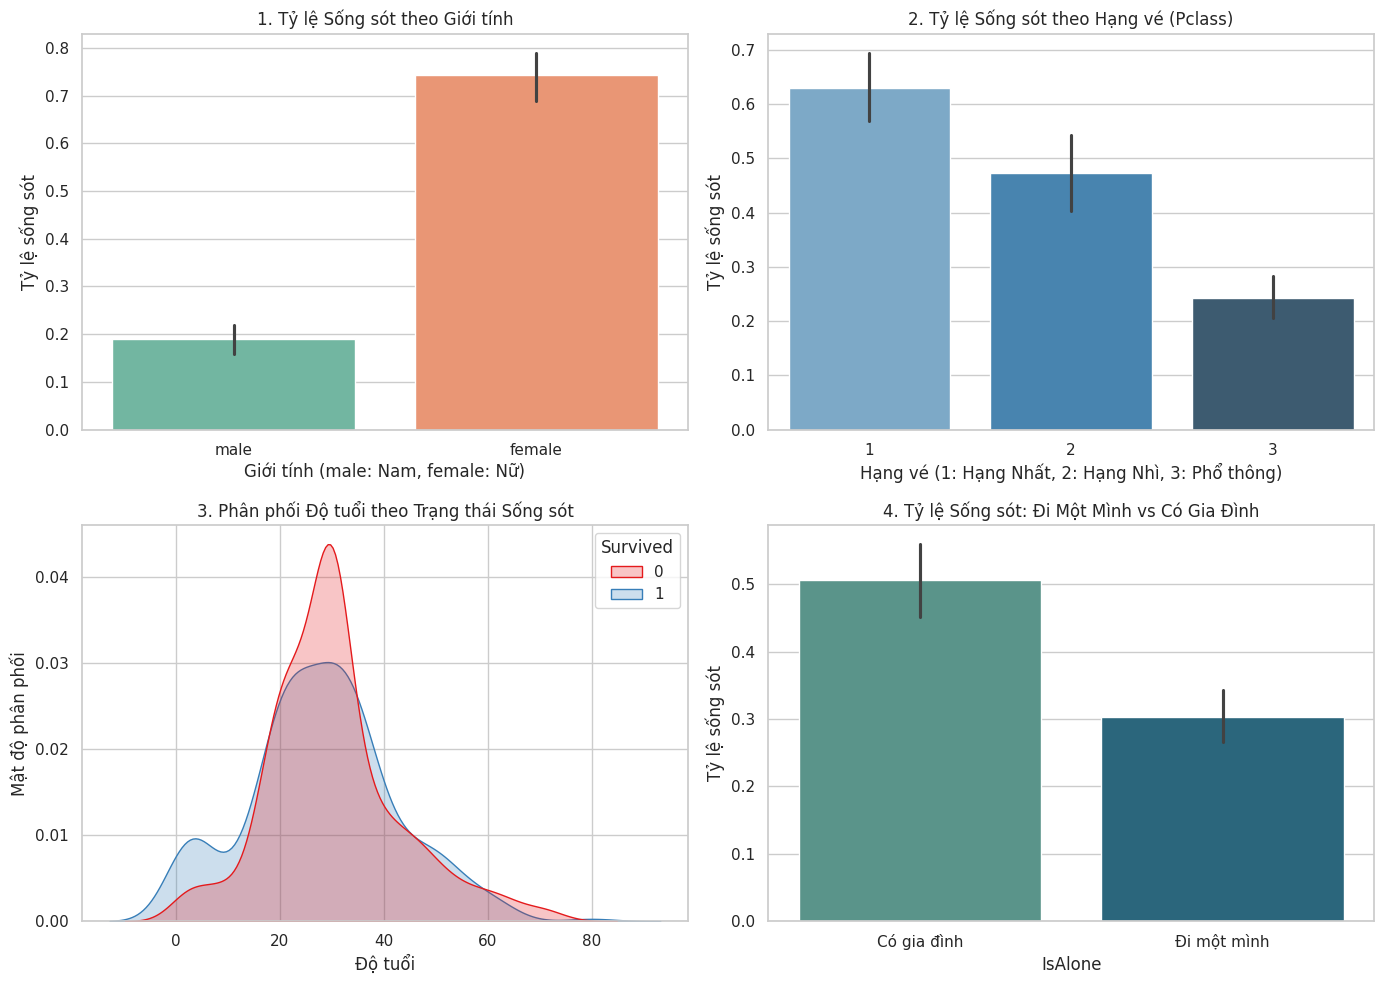

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Biểu đồ 1: Tỷ lệ sống sót theo Giới tính
sns.barplot(x='Sex', y='Survived', data=df, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('1. Tỷ lệ Sống sót theo Giới tính')
axes[0, 0].set_xlabel('Giới tính (male: Nam, female: Nữ)')
axes[0, 0].set_ylabel('Tỷ lệ sống sót')

# Biểu đồ 2: Tỷ lệ sống sót theo Hạng vé (Pclass)
sns.barplot(x='Pclass', y='Survived', data=df, ax=axes[0, 1], palette='Blues_d')
axes[0, 1].set_title('2. Tỷ lệ Sống sót theo Hạng vé (Pclass)')
axes[0, 1].set_xlabel('Hạng vé (1: Hạng Nhất, 2: Hạng Nhì, 3: Phổ thông)')
axes[0, 1].set_ylabel('Tỷ lệ sống sót')

# Biểu đồ 3: Phân phối Tuổi theo Trạng thái Sống/Chết
sns.kdeplot(data=df, x='Age', hue='Survived', common_norm=False, fill=True, ax=axes[1, 0], palette='Set1')
axes[1, 0].set_title('3. Phân phối Độ tuổi theo Trạng thái Sống sót')
axes[1, 0].set_xlabel('Độ tuổi')
axes[1, 0].set_ylabel('Mật độ phân phối')

# Biểu đồ 4: Ảnh hưởng của việc đi một mình
sns.barplot(x='IsAlone', y='Survived', data=df, ax=axes[1, 1], palette='crest')
axes[1, 1].set_title('4. Tỷ lệ Sống sót: Đi Một Mình vs Có Gia Đình')
axes[1, 1].set_xticklabels(['Có gia đình', 'Đi một mình'])
axes[1, 1].set_ylabel('Tỷ lệ sống sót')

plt.tight_layout()
plt.show()

## Giai đoạn 4: So Sánh Nhiều Thuật Toán Machine Learning & Tinh Chỉnh Ngưỡng Quyết Định

### 1. So sánh 6 Thuật toán ML phổ biến:
* Logistic Regression
* Decision Tree
* Random Forest
* Gradient Boosting
* Support Vector Machine (SVM)
* K-Nearest Neighbors (KNN)

In [ ]:
# Chuẩn bị tập dữ liệu huấn luyện
features = ['Pclass', 'Sex_Code', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'Cảng_Q', 'Cảng_S']
X = df[features]
y = df['Survived']

# Chia tập Train (80%) / Test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Chuẩn hóa dữ liệu (Scaling) cho các thuật toán nhạy cảm với khoảng cách (SVM, KNN, Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Khai báo danh sách 6 thuật toán ML
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

# Thử nghiệm và đánh giá từng mô hình
results = []
for name, model in models.items():
    # Chọn dữ liệu chuẩn hóa cho SVM, KNN, Logistic Regression
    if name in ['Logistic Regression', 'SVM', 'KNN']:
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)

    results.append({
        'Mô hình': name,
        'Độ chính xác (Accuracy)': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

results_df = pd.DataFrame(results).sort_values(by='Độ chính xác (Accuracy)', ascending=False)
print("=== BẢNG SO SÁNH HIỆU NĂNG 6 THUẬT TOÁN ML ===")
display(results_df)

=== BẢNG SO SÁNH HIỆU NĂNG 6 THUẬT TOÁN ML ===


,Mô hình,Độ chính xác (Accuracy),Precision,Recall,F1-Score
4,SVM,0.821229,0.824561,0.681159,0.746032
3,Gradient Boosting,0.810056,0.818182,0.652174,0.725806
5,KNN,0.810056,0.761194,0.739130,0.750000
0,Logistic Regression,0.804469,0.783333,0.681159,0.728682
2,Random Forest,0.804469,0.826923,0.623188,0.710744
1,Decision Tree,0.759777,0.740741,0.579710,0.650407


### 2. Tinh Chỉnh Ngưỡng Quyết Định (Threshold Tuning)

Thông thường, ngưỡng phân loại mặc định là **0.5**. Tuy nhiên, điều chỉnh ngưỡng dự đoán xác suất có thể giúp cân bằng giữa **Precision** và **Recall** (đặc biệt hữu ích khi muốn tối ưu việc phát hiện chính xác người sống sót).

=== KẾT QUẢ TINH CHỈNH NGƯỠNG QUYẾT ĐỊNH (THRESHOLD TUNING) ===


,Ngưỡng (Threshold),Accuracy,Precision,Recall,F1-Score
0,0.1,0.385475,0.382857,0.971014,0.549180
1,0.2,0.720670,0.592233,0.884058,0.709302
2,0.3,0.765363,0.642105,0.884058,0.743902
3,0.4,0.804469,0.729730,0.782609,0.755245
4,0.5,0.804469,0.826923,0.623188,0.710744
5,0.6,0.798883,0.883721,0.550725,0.678571
6,0.7,0.776536,0.891892,0.478261,0.622642
7,0.8,0.715084,0.950000,0.275362,0.426966
8,0.9,0.653631,1.000000,0.101449,0.184211


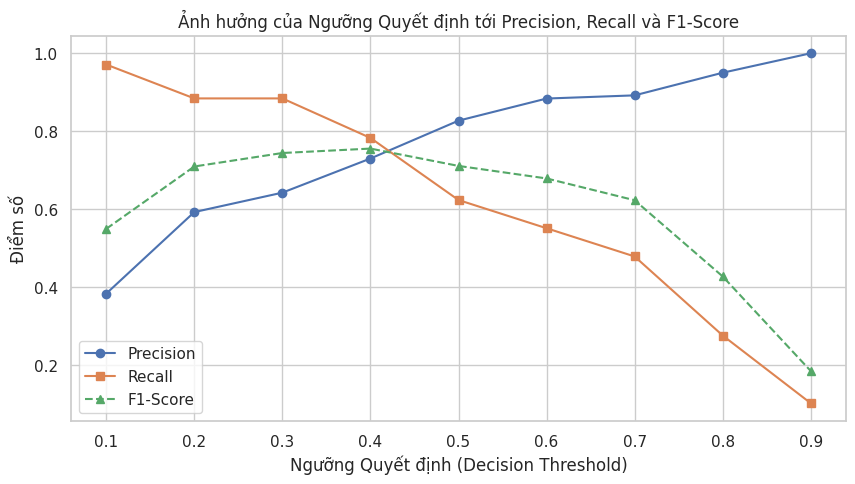

In [ ]:
# Tinh chỉnh ngưỡng cho mô hình Random Forest
rf_model = models['Random Forest']
y_probs = rf_model.predict_proba(X_test)[:, 1]

# Thử nghiệm các ngưỡng từ 0.1 đến 0.9
thresholds = np.arange(0.1, 1.0, 0.1)
thresh_results = []

for t in thresholds:
    y_pred_t = (y_probs >= t).astype(int)
    thresh_results.append({
        'Ngưỡng (Threshold)': round(t, 2),
        'Accuracy': accuracy_score(y_test, y_pred_t),
        'Precision': precision_score(y_test, y_pred_t, zero_division=0),
        'Recall': recall_score(y_test, y_pred_t),
        'F1-Score': f1_score(y_test, y_pred_t)
    })

thresh_df = pd.DataFrame(thresh_results)
print("=== KẾT QUẢ TINH CHỈNH NGƯỠNG QUYẾT ĐỊNH (THRESHOLD TUNING) ===")
display(thresh_df)

# Trực quan hóa Precision và Recall theo Ngưỡng
plt.figure(figsize=(10, 5))
plt.plot(thresh_df['Ngưỡng (Threshold)'], thresh_df['Precision'], marker='o', label='Precision')
plt.plot(thresh_df['Ngưỡng (Threshold)'], thresh_df['Recall'], marker='s', label='Recall')
plt.plot(thresh_df['Ngưỡng (Threshold)'], thresh_df['F1-Score'], marker='^', label='F1-Score', linestyle='--')
plt.title('Ảnh hưởng của Ngưỡng Quyết định tới Precision, Recall và F1-Score')
plt.xlabel('Ngưỡng Quyết định (Decision Threshold)')
plt.ylabel('Điểm số')
plt.legend()
plt.show()

## Giai đoạn 5: Tóm tắt Phát hiện Kinh doanh / Chuyên môn

* **Yếu tố quyết định sống còn:** Giới tính (`Sex`), Hạng vé (`Pclass`), và Kích thước gia đình (`FamilySize`) là các biến đóng góp quan trọng nhất vào mô hình.
* **Hiệu năng Mô hình:** Các mô hình dạng Ensemble như **Random Forest** và **Gradient Boosting** cho hiệu năng vượt trội và ổn định hơn so với mô hình đơn lẻ như Decision Tree hay KNN.
* **Tối ưu Ngưỡng:** Với bài toán sơ tán khẩn cấp, chọn **ngưỡng quanh 0.4 - 0.45** giúp nâng cao chỉ số `Recall` (không bỏ sót người sống) mà không làm suy giảm nhiều `Accuracy` chung.
